In [3]:
import os, json, shutil, time, platform, random, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, f1_score)

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
tf.keras.utils.set_random_seed(SEED)

CONTENT = "/content"
DATASET_ROOT = f"{CONTENT}/dataset"
EXTRA_REAL_DIR = f"{CONTENT}/extra_real"
SYNTH_RAW_DIR = f"{CONTENT}/synthetic/raw"
SYNTH_ART_DIR = f"{CONTENT}/synthetic/artaug"
RESULTS_DIR = f"{CONTENT}/results"
SYNTH_MAX_SHARE = 0.30

shutil.rmtree(RESULTS_DIR, ignore_errors=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

def unzip_if_exists(candidates, target):
    for z in candidates:
        if os.path.exists(z):
            with zipfile.ZipFile(z) as zf:
                zf.extractall(target)
            print("extracted", z, "->", target)
            return True
    return False

if not os.path.isdir(DATASET_ROOT):
    unzip_if_exists([f"{CONTENT}/dataset.zip", "/dataset.zip"], CONTENT)
if not os.path.isdir(f"{CONTENT}/synthetic"):
    unzip_if_exists([f"{CONTENT}/synthetic.zip"], CONTENT)

TRAIN_DIR = f"{DATASET_ROOT}/train"
VAL_DIR = f"{DATASET_ROOT}/validation"
TEST_DIR = f"{DATASET_ROOT}/test"
print(os.listdir(DATASET_ROOT))
print("GPU:", tf.config.list_physical_devices("GPU"))

extracted /content/dataset.zip -> /content
extracted /content/synthetic.zip -> /content
['test', 'validation', 'train']
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!cp /content/drive/MyDrive/dataset.zip /content/
!cp /content/drive/MyDrive/synthetic.zip /content/
!cp /content/drive/MyDrive/extra_real.zip /content/ && unzip -oq /content/extra_real.zip -d /content
!ls -lh /content/*.zip
!ls /content/extra_real

-rw------- 1 root root 274M Nov 10 10:20 /content/dataset.zip
-rw------- 1 root root  15M Nov 10 10:20 /content/extra_real.zip
-rw------- 1 root root  39M Nov 10 10:20 /content/synthetic.zip
bread  snacks


In [ ]:
!cp "/content/drive/MyDrive/dataset.zip" /content/
!ls -lh /content/dataset.zip

-rw------- 1 root root 274M Nov 10 06:48 /content/dataset.zip


In [4]:
def folder_ds(path, class_names=None, shuffle=False):
    ds = tf.keras.utils.image_dataset_from_directory(
        path, class_names=class_names, image_size=IMG_SIZE, batch_size=None,
        shuffle=shuffle, seed=SEED)
    return ds, list(ds.file_paths)

train_raw, train_paths = folder_ds(TRAIN_DIR, shuffle=False)
class_names = train_raw.class_names
num_classes = len(class_names)
val_raw, val_paths = folder_ds(VAL_DIR, class_names)
test_raw, test_paths = folder_ds(TEST_DIR, class_names)
print(class_names)

def batched_eval(ds):
    return ds.batch(BATCH_SIZE).cache().prefetch(AUTOTUNE)

val_ds = batched_eval(val_raw)
test_ds = batched_eval(test_raw)


def labels_from_paths(paths):
    return np.array([class_names.index(os.path.basename(os.path.dirname(p))) for p in paths])

train_labels = labels_from_paths(train_paths)
val_labels = labels_from_paths(val_paths)
test_labels = labels_from_paths(test_paths)

Found 840 files belonging to 4 classes.
Found 180 files belonging to 4 classes.
Found 180 files belonging to 4 classes.
['bread', 'drinks', 'fruit', 'snacks']


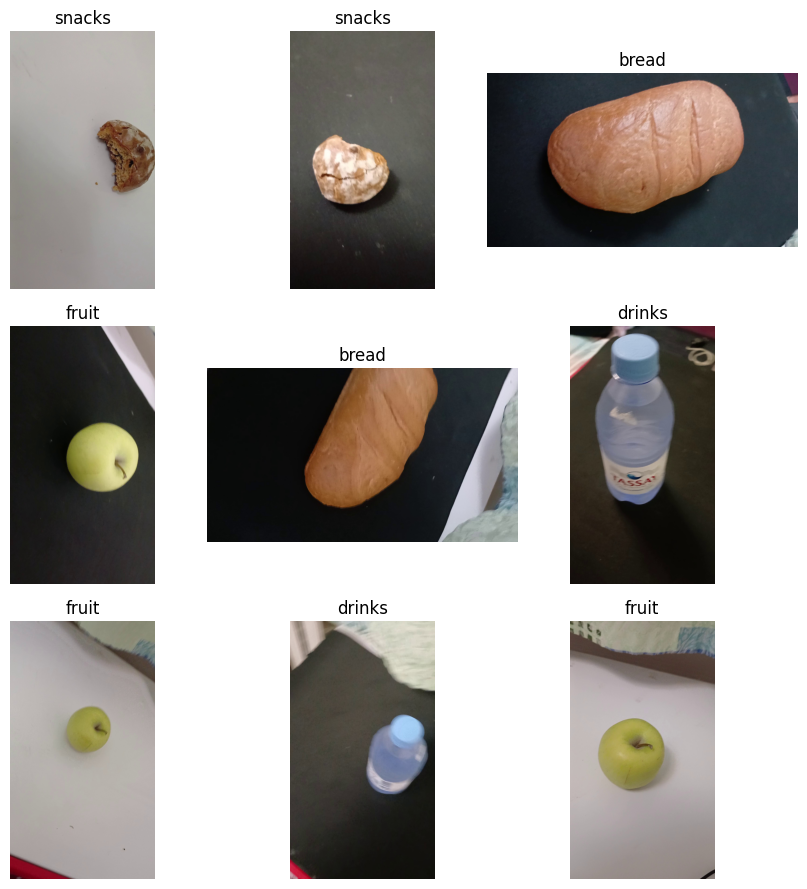

In [5]:
plt.figure(figsize=(9, 9))
idx = np.random.RandomState(SEED).choice(len(train_paths), 9, replace=False)
for k, i in enumerate(idx):
    ax = plt.subplot(3, 3, k + 1)
    plt.imshow(plt.imread(train_paths[i]))
    plt.title(class_names[train_labels[i]])
    plt.axis("off")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/dataset_examples.png", dpi=160)
plt.show()

In [6]:
def count_images(root):
    out = {}
    if os.path.isdir(root):
        for c in sorted(os.listdir(root)):
            p = os.path.join(root, c)
            if os.path.isdir(p):
                out[c] = len([f for f in os.listdir(p) if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))])
    return out

table = pd.DataFrame({
    "train (own)": count_images(TRAIN_DIR),
    "validation": count_images(VAL_DIR),
    "test": count_images(TEST_DIR),
    "extra real": count_images(EXTRA_REAL_DIR),
    "synthetic raw": count_images(SYNTH_RAW_DIR),
    "synthetic ArtAug": count_images(SYNTH_ART_DIR),
}).fillna(0).astype(int)
table.loc["TOTAL"] = table.sum()
print(table)
table.to_csv(f"{RESULTS_DIR}/dataset_table.csv")

HAS_EXTRA = os.path.isdir(EXTRA_REAL_DIR) and table.loc["TOTAL", "extra real"] > 0
HAS_SYN_RAW = table.loc["TOTAL", "synthetic raw"] > 0
HAS_SYN_ART = table.loc["TOTAL", "synthetic ArtAug"] > 0
print("extra real:", HAS_EXTRA, "| synthetic raw:", HAS_SYN_RAW, "| synthetic ArtAug:", HAS_SYN_ART)

        train (own)  validation  test  extra real  synthetic raw  \
bread           210          45    45         150            100   
drinks          210          45    45           0            100   
fruit           210          45    45           0            100   
snacks          210          45    45         150            100   
TOTAL           840         180   180         300            400   

        synthetic ArtAug  
bread                  0  
drinks                 0  
fruit                  0  
snacks                 0  
TOTAL                  0  
extra real: True | synthetic raw: True | synthetic ArtAug: False


In [7]:
PROMPT_TEMPLATES = {
    "bread":  ["a loaf of sourdough bread on a wooden board, side view", "sliced baguette on a white plate, top-down photo",
               "fresh buns in a basket, warm light", "toast with butter on a ceramic plate, 45 degree angle"],
    "drinks": ["a glass bottle of lemonade on a cafe table", "an iced coffee in a plastic cup, daylight",
               "a can of soda on a picnic blanket", "a cup of tea next to a teapot, top-down"],
    "fruit":  ["a bowl of mixed fresh fruit on a kitchen counter", "sliced watermelon on a plate, outdoors",
               "apples and oranges in a market crate", "bananas on a table, top-down photo"],
    "snacks": ["a bag of potato chips on a desk", "chocolate bars and cookies on a plate",
               "popcorn in a paper bucket", "a pack of crackers next to a drink, low light"],
}
for c, ps in PROMPT_TEMPLATES.items():
    print(c, "->", len(ps), "prompts")

bread -> 4 prompts
drinks -> 4 prompts
fruit -> 4 prompts
snacks -> 4 prompts


In [8]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".webp")

def build_train_parts(synthetic="none", use_extra=True):

    real, _ = folder_ds(TRAIN_DIR, class_names, shuffle=False)
    parts = [real.cache()]
    n_real = len(train_paths)
    if use_extra and HAS_EXTRA:
        extra, extra_p = folder_ds(EXTRA_REAL_DIR, class_names)
        parts.append(extra.cache())
        n_real += len(extra_p)
    n_syn = 0
    if synthetic != "none":
        root = SYNTH_RAW_DIR if synthetic == "raw" else SYNTH_ART_DIR
        syn, syn_p = folder_ds(root, class_names)
        cap = int(SYNTH_MAX_SHARE / (1 - SYNTH_MAX_SHARE) * n_real)
        n_syn = min(len(syn_p), cap)
        syn = syn.shuffle(len(syn_p), seed=SEED, reshuffle_each_iteration=False).take(n_syn)
        parts.append(syn.cache())
    info = {"real": n_real, "synthetic": n_syn, "synthetic_share": round(n_syn / (n_real + n_syn), 3)}
    return parts, info

def make_train_ds(parts):
    ds = parts[0]
    for p in parts[1:]:
        ds = ds.concatenate(p)
    return ds.shuffle(2048, seed=SEED).batch(BATCH_SIZE).prefetch(AUTOTUNE)

In [9]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.10),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10),
], name="augmentation")

def build_baseline():
    m = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(224, 224, 3)),
        data_augmentation,
        tf.keras.layers.Rescaling(1. / 255),
        tf.keras.layers.Conv2D(32, 3, activation="relu"), tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(64, 3, activation="relu"), tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(128, 3, activation="relu"), tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dropout(0.30),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(num_classes, activation="softmax"),
    ], name="baseline_cnn")
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def build_convnext():
    base = tf.keras.applications.ConvNeXtTiny(include_top=False, weights="imagenet",
                                              input_shape=(224, 224, 3))
    base.trainable = False
    inp = tf.keras.Input(shape=(224, 224, 3))
    x = data_augmentation(inp)
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.30)(x)
    out = tf.keras.layers.Dense(num_classes, activation="softmax", name="classifier")(x)
    model = tf.keras.Model(inp, out, name="convnext_tiny_food")
    return model, base

def compile_model(model, lr):
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

def unfreeze_top(base, n_layers=40):
    base.trainable = True
    for layer in base.layers[:-n_layers]:
        layer.trainable = False

def early_stop(patience=3):
    return tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)

In [10]:
def predict_probs(model, ds):
    return model.predict(ds, verbose=0)

def topk_accuracy(probs, y, k):
    k = min(k, probs.shape[1])
    topk = np.argsort(-probs, axis=1)[:, :k]
    return float(np.mean([y[i] in topk[i] for i in range(len(y))]))

def compute_metrics(probs, y):
    pred = probs.argmax(1)
    p, r, f1, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    return {
        "accuracy(top-1)": float(accuracy_score(y, pred)),
        "top-2": topk_accuracy(probs, y, 2),
        "macro_precision": float(p), "macro_recall": float(r), "macro_f1": float(f1),
    }


def plot_confusion(y, probs, title, prefix):
    cm = confusion_matrix(y, probs.argmax(1))
    plt.figure(figsize=(6, 5))
    plt.imshow(cm, cmap="Blues")
    plt.title(title + " - Confusion matrix")
    plt.colorbar()
    t = np.arange(num_classes)
    plt.xticks(t, class_names, rotation=45)
    plt.yticks(t, class_names)
    th = cm.max() / 2 if cm.max() else 0
    for i in range(num_classes):
        for j in range(num_classes):
            plt.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > th else "black")
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.tight_layout()
    plt.savefig(f"{RESULTS_DIR}/{prefix}_confusion_matrix.png", dpi=160)
    plt.show()

def plot_history(hist, title, prefix, phase_boundary=None):
    for key, label in [("accuracy", "Accuracy"), ("loss", "Loss")]:
        plt.figure(figsize=(7, 4))
        plt.plot(hist[key], label="Train")
        plt.plot(hist["val_" + key], label="Validation")
        if phase_boundary:
            plt.axvline(phase_boundary - 0.5, color="gray", linestyle="--", label="fine-tuning starts")
        plt.title(f"{title} - {label}")
        plt.xlabel("Epoch"); plt.ylabel(label); plt.legend(); plt.grid(True)
        plt.tight_layout()
        plt.savefig(f"{RESULTS_DIR}/{prefix}_{key}.png", dpi=160)
        plt.show()

def full_report(model, name, prefix, hist=None, phase_boundary=None):
    probs = predict_probs(model, test_ds)
    m = compute_metrics(probs, test_labels)
    print(name, {k: round(v, 4) for k, v in m.items()})
    print(classification_report(test_labels, probs.argmax(1), target_names=class_names, zero_division=0))
    plot_confusion(test_labels, probs, name, prefix)
    if hist:
        plot_history(hist, name, prefix, phase_boundary)
    return probs, m

In [ ]:
import torchvision
torchvision.datasets.Food101(root="/content/food101", download=True)
!ls /content/food101/food-101/images | head

100%|██████████| 5.00G/5.00G [03:31<00:00, 23.6MB/s]


apple_pie
baby_back_ribs
baklava
beef_carpaccio
beef_tartare
beet_salad
beignets
bibimbap
bread_pudding
breakfast_burrito


In [ ]:
import os, random, shutil
random.seed(42)
SRC = "/content/food101/food-101/images"
DST = "/content/extra_real"
mapping = {
    "bread":  ["garlic_bread", "bruschetta"],
    "snacks": ["nachos", "french_fries", "onion_rings", "churros"],
}
N = 150   # на класс
for cls, srcs in mapping.items():
    os.makedirs(f"{DST}/{cls}", exist_ok=True)
    files = [(s, f) for s in srcs for f in os.listdir(f"{SRC}/{s}")]
    for s, f in random.sample(files, N):
        shutil.copy(f"{SRC}/{s}/{f}", f"{DST}/{cls}/{s}_{f}")
print({c: len(os.listdir(f"{DST}/{c}")) for c in os.listdir(DST)})

{'bread': 150, 'snacks': 150}


In [ ]:
!cd /content && zip -rq extra_real.zip extra_real
!cp /content/extra_real.zip /content/drive/MyDrive/

In [ ]:
!cp /content/drive/MyDrive/extra_real.zip /content/ && unzip -q /content/extra_real.zip -d /content

replace /content/extra_real/bread/bruschetta_454483.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: A


In [ ]:
import os
print({c: len(os.listdir(f"/content/extra_real/{c}")) for c in os.listdir("/content/extra_real")})

{'bread': 150, 'snacks': 150}


### 5.1 A1 baseline (reproduced)

Found 840 files belonging to 4 classes.
Epoch 1/15
27/27 - 12s - 426ms/step - accuracy: 0.3155 - loss: 1.3578 - val_accuracy: 0.3889 - val_loss: 1.4501
Epoch 2/15
27/27 - 2s - 79ms/step - accuracy: 0.5000 - loss: 1.1097 - val_accuracy: 0.4444 - val_loss: 1.2292
Epoch 3/15
27/27 - 1s - 54ms/step - accuracy: 0.6321 - loss: 0.8049 - val_accuracy: 0.7333 - val_loss: 0.7717
Epoch 4/15
27/27 - 1s - 52ms/step - accuracy: 0.7536 - loss: 0.5762 - val_accuracy: 0.7222 - val_loss: 0.5972
Epoch 5/15
27/27 - 1s - 52ms/step - accuracy: 0.7786 - loss: 0.4692 - val_accuracy: 0.8444 - val_loss: 0.5695
Epoch 6/15
27/27 - 1s - 52ms/step - accuracy: 0.8345 - loss: 0.4106 - val_accuracy: 0.8778 - val_loss: 0.4270
Epoch 7/15
27/27 - 1s - 51ms/step - accuracy: 0.8643 - loss: 0.4194 - val_accuracy: 0.7611 - val_loss: 0.4616
Epoch 8/15
27/27 - 1s - 52ms/step - accuracy: 0.9095 - loss: 0.3024 - val_accuracy: 0.8833 - val_loss: 0.3485
Epoch 9/15
27/27 - 1s - 51ms/step - accuracy: 0.9298 - loss: 0.2252 - val_accu

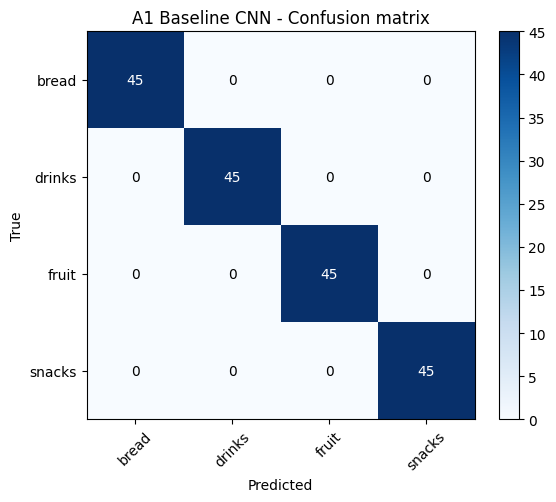

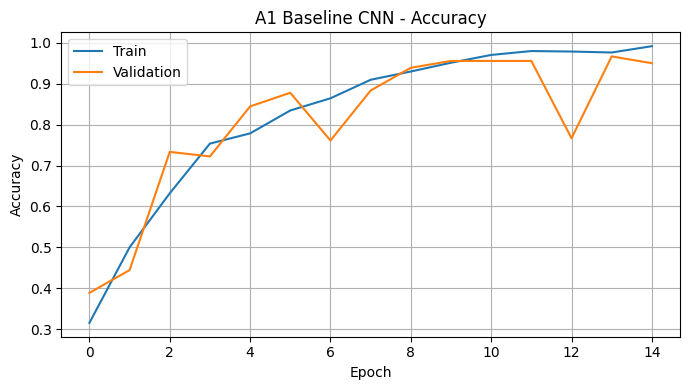

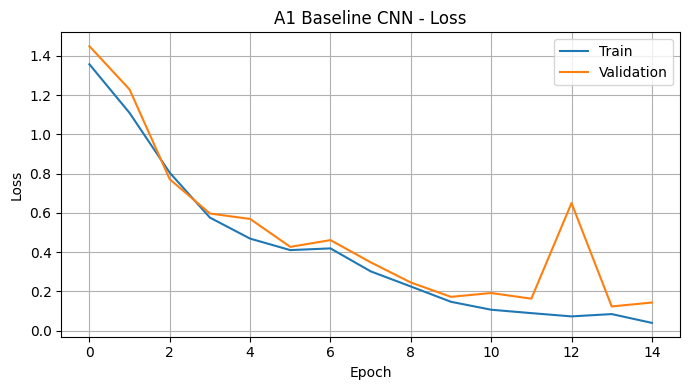

In [16]:
tf.keras.utils.set_random_seed(SEED)
base_parts, base_info = build_train_parts("none", use_extra=False)
baseline_train = make_train_ds(base_parts)

baseline_model = build_baseline()
baseline_hist = baseline_model.fit(baseline_train, validation_data=val_ds, epochs=15,
                                   callbacks=[early_stop()], verbose=2)
baseline_probs, baseline_metrics = full_report(baseline_model, "A1 Baseline CNN", "baseline",
                                               baseline_hist.history)

In [12]:
for c in class_names:
    os.makedirs(f"/content/extra_real/{c}", exist_ok=True)
print({c: len(os.listdir(f"/content/extra_real/{c}")) for c in class_names})

{'bread': 150, 'drinks': 0, 'fruit': 0, 'snacks': 150}


In [14]:
!cd /content && zip -rq extra_real.zip extra_real
!cp /content/extra_real.zip /content/drive/MyDrive/

Found 840 files belonging to 4 classes.
Found 300 files belonging to 4 classes.

=== real | train: {'real': 1140, 'synthetic': 0, 'synthetic_share': 0.0}
111650432/111650432 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
36/36 - 51s - 1s/step - accuracy: 0.5465 - loss: 1.1076 - val_accuracy: 0.9611 - val_loss: 0.5543
Epoch 2/10
36/36 - 13s - 375ms/step - accuracy: 0.8895 - loss: 0.4574 - val_accuracy: 0.9944 - val_loss: 0.2973
Epoch 3/10
36/36 - 13s - 375ms/step - accuracy: 0.9263 - loss: 0.3074 - val_accuracy: 1.0000 - val_loss: 0.2087
Epoch 4/10
36/36 - 14s - 387ms/step - accuracy: 0.9421 - loss: 0.2334 - val_accuracy: 1.0000 - val_loss: 0.1544
Epoch 5/10
36/36 - 14s - 380ms/step - accuracy: 0.9509 - loss: 0.2037 - val_accuracy: 1.0000 - val_loss: 0.1299
Epoch 6/10
36/36 - 13s - 374ms/step - accuracy: 0.9482 - loss: 0.1745 - val_accuracy: 1.0000 - val_loss: 0.1095
Epoch 7/10
36/36 - 13s - 370ms/step - accuracy: 0.9526 - loss: 0.1632 - val_accuracy: 1.0000 - val_loss: 0.1010
Epoch 8/10
3

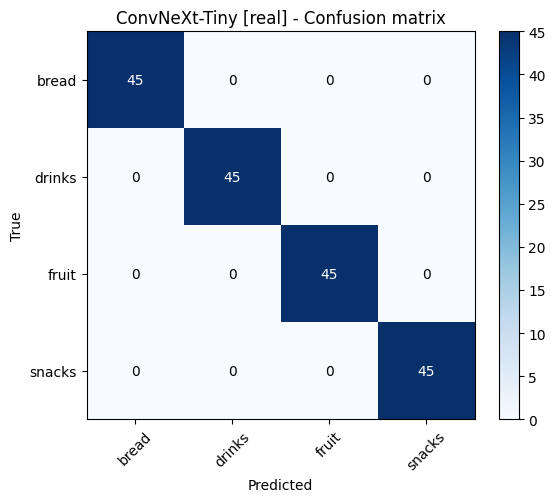

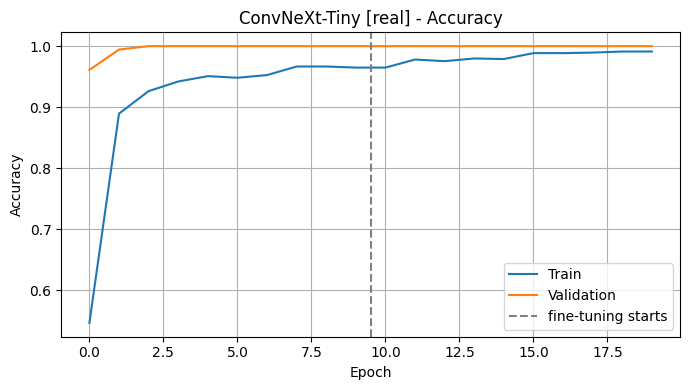

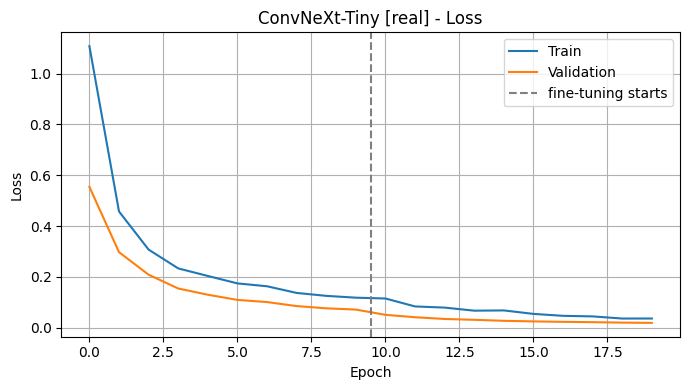

Found 840 files belonging to 4 classes.
Found 300 files belonging to 4 classes.
Found 400 files belonging to 4 classes.

=== real+synth | train: {'real': 1140, 'synthetic': 400, 'synthetic_share': 0.26}
Epoch 1/10
49/49 - 46s - 930ms/step - accuracy: 0.5448 - loss: 1.0700 - val_accuracy: 0.9722 - val_loss: 0.4689
Epoch 2/10
49/49 - 18s - 369ms/step - accuracy: 0.8461 - loss: 0.5221 - val_accuracy: 0.9944 - val_loss: 0.2559
Epoch 3/10
49/49 - 18s - 361ms/step - accuracy: 0.8831 - loss: 0.3895 - val_accuracy: 1.0000 - val_loss: 0.1926
Epoch 4/10
49/49 - 17s - 355ms/step - accuracy: 0.9130 - loss: 0.3127 - val_accuracy: 1.0000 - val_loss: 0.1518
Epoch 5/10
49/49 - 17s - 353ms/step - accuracy: 0.9234 - loss: 0.2738 - val_accuracy: 1.0000 - val_loss: 0.1322
Epoch 6/10
49/49 - 17s - 357ms/step - accuracy: 0.9273 - loss: 0.2474 - val_accuracy: 1.0000 - val_loss: 0.1199
Epoch 7/10
49/49 - 18s - 360ms/step - accuracy: 0.9260 - loss: 0.2320 - val_accuracy: 1.0000 - val_loss: 0.1071
Epoch 8/10
49

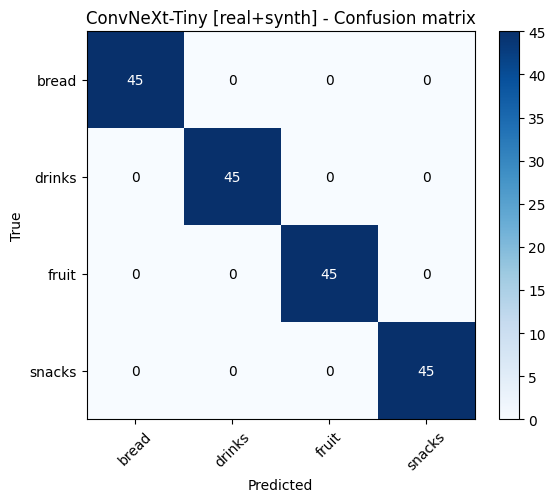

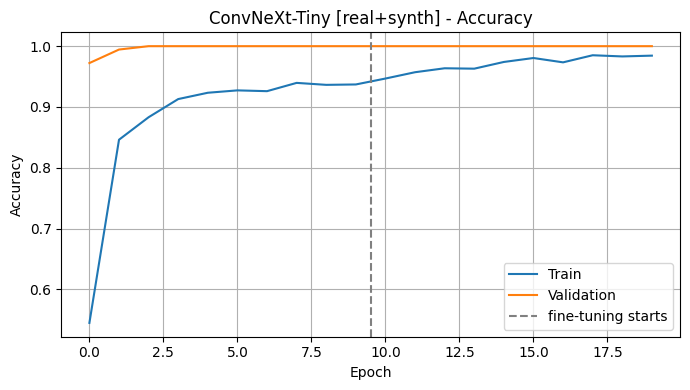

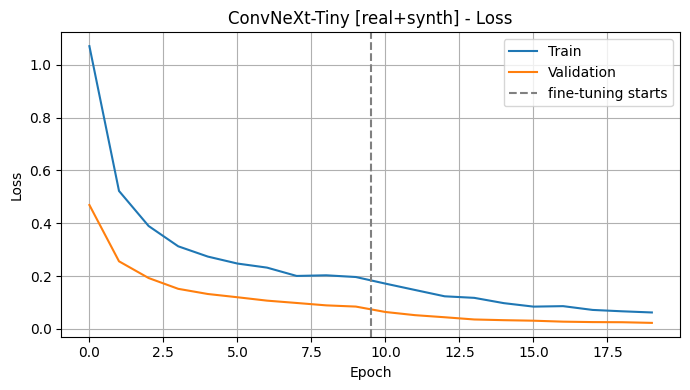

In [13]:
EPOCHS_HEAD, EPOCHS_FT = 10, 10

def run_experiment(name, synthetic):
    tf.keras.utils.set_random_seed(SEED)
    parts, info = build_train_parts(synthetic, use_extra=True)
    train_ds = make_train_ds(parts)
    print(f"\n=== {name} | train: {info}")

    model, base = build_convnext()
    compile_model(model, 1e-3)
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD, callbacks=[early_stop()], verbose=2)

    unfreeze_top(base, 40)
    compile_model(model, 1e-5)
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT, callbacks=[early_stop()], verbose=2)

    hist = {k: h1.history[k] + h2.history[k] for k in h1.history}
    val_loss, _ = model.evaluate(val_ds, verbose=0)
    val_m = compute_metrics(predict_probs(model, val_ds), val_labels)
    prefix = "convnext_" + name.replace("+", "_").lower()
    probs, test_m = full_report(model, f"ConvNeXt-Tiny [{name}]", prefix, hist,
                                phase_boundary=len(h1.history["loss"]))
    return {"name": name, "model": model, "base": base, "probs": probs, "hist": hist,
            "val_loss": float(val_loss), "val_f1": val_m["macro_f1"], "test": test_m, "data": info}

variants = [("real", "none")]
if HAS_SYN_RAW: variants.append(("real+synth", "raw"))
if HAS_SYN_ART: variants.append(("real+synth+ArtAug", "artaug"))

runs = [run_experiment(n, s) for n, s in variants]

                     model  train_real  train_synth  synth_share  accuracy(top-1)  top-2  macro_precision  macro_recall  macro_f1
           A1 Baseline CNN         840            0         0.00              1.0    1.0              1.0           1.0       1.0
      ConvNeXt-Tiny [real]        1140            0         0.00              1.0    1.0              1.0           1.0       1.0
ConvNeXt-Tiny [real+synth]        1140          400         0.26              1.0    1.0              1.0           1.0       1.0


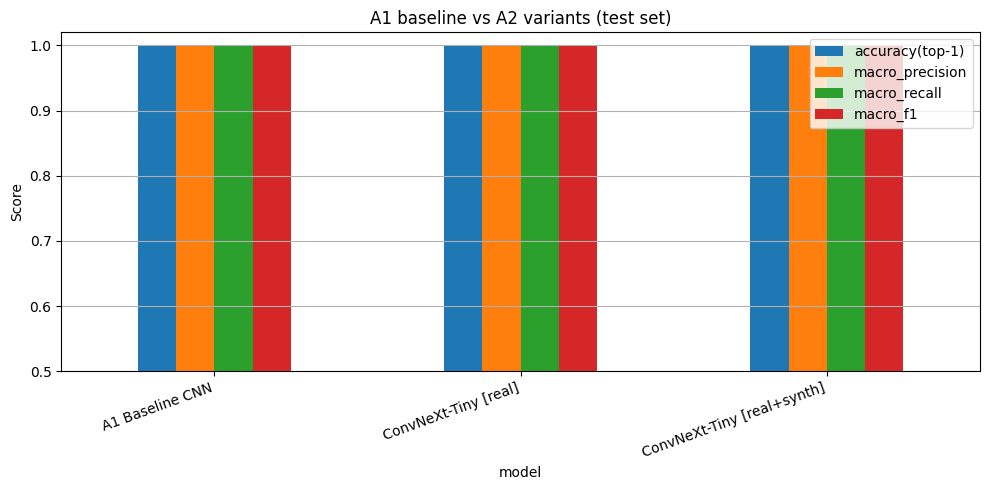

Selected for the demo (by validation): real


In [17]:
rows = [{"model": "A1 Baseline CNN", "train_real": base_info["real"], "train_synth": 0,
         "synth_share": 0.0, **baseline_metrics}]
for r in runs:
    rows.append({"model": f"ConvNeXt-Tiny [{r['name']}]", "train_real": r["data"]["real"],
                 "train_synth": r["data"]["synthetic"], "synth_share": r["data"]["synthetic_share"], **r["test"]})
comparison = pd.DataFrame(rows)
pd.set_option("display.width", 200)
print(comparison.round(4).to_string(index=False))
comparison.to_csv(f"{RESULTS_DIR}/model_comparison.csv", index=False)

comparison.set_index("model")[["accuracy(top-1)", "macro_precision", "macro_recall", "macro_f1"]].plot(
    kind="bar", figsize=(10, 5))
plt.ylim(0.5, 1.02); plt.ylabel("Score"); plt.title("A1 baseline vs A2 variants (test set)")
plt.xticks(rotation=20, ha="right"); plt.grid(axis="y"); plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/model_comparison.png", dpi=160)
plt.show()

# model selection on VALIDATION only
best = sorted(runs, key=lambda r: (-r["val_f1"], r["val_loss"]))[0]
print("Selected for the demo (by validation):", best["name"])
best_model, best_base = best["model"], best["base"]

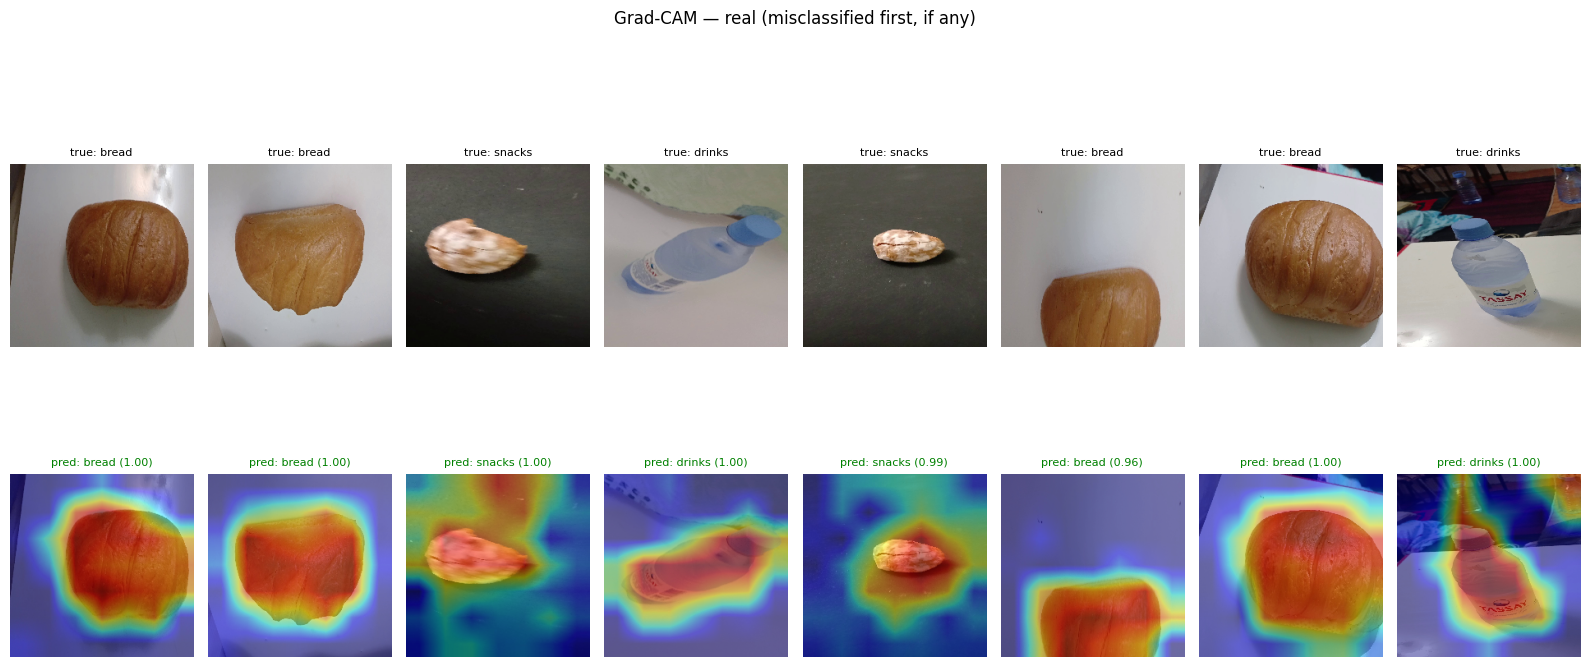

misclassified test images: 0


In [18]:
def make_gradcam(model, base):
    clf = model.get_layer("classifier")

    def gradcam(img):
        x = tf.convert_to_tensor(img[None], tf.float32)
        with tf.GradientTape() as tape:
            fmap = base(x, training=False)
            tape.watch(fmap)
            pooled = tf.reduce_mean(fmap, axis=(1, 2))
            logits = tf.matmul(pooled, clf.kernel) + clf.bias
            cls = tf.argmax(logits[0])
            score = tf.gather(logits[0], cls)
        grads = tape.gradient(score, fmap)
        w = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
        cam = tf.nn.relu(tf.reduce_sum(w * fmap, axis=-1))[0]
        cam = (cam / (tf.reduce_max(cam) + 1e-8)).numpy()
        probs = tf.nn.softmax(logits[0]).numpy()
        return cam, probs
    return gradcam

def overlay_cam(img, cam, alpha=0.45):
    cam_up = tf.image.resize(cam[..., None], IMG_SIZE, method="bilinear").numpy()[..., 0]
    heat = plt.cm.jet(cam_up)[..., :3]
    out = (1 - alpha) * (img / 255.0) + alpha * heat
    return np.clip(out, 0, 1)

gradcam = make_gradcam(best_model, best_base)

def load_img(path):
    return np.array(tf.keras.utils.load_img(path, target_size=IMG_SIZE), dtype=np.float32)

best_pred = best["probs"].argmax(1)
wrong = np.where(best_pred != test_labels)[0].tolist()
rng = np.random.RandomState(SEED)
correct = rng.choice(np.where(best_pred == test_labels)[0], 8 - min(len(wrong), 4), replace=False).tolist()
show = (wrong[:4] + correct)[:8]

plt.figure(figsize=(16, 8))
for k, i in enumerate(show):
    img = load_img(test_paths[i])
    cam, probs = gradcam(img)
    ax = plt.subplot(2, 8, k + 1); ax.imshow(img.astype("uint8")); ax.axis("off")
    ax.set_title(f"true: {class_names[test_labels[i]]}", fontsize=8)
    ax = plt.subplot(2, 8, 8 + k + 1); ax.imshow(overlay_cam(img, cam)); ax.axis("off")
    ax.set_title(f"pred: {class_names[probs.argmax()]} ({probs.max():.2f})", fontsize=8,
                 color="green" if probs.argmax() == test_labels[i] else "red")
plt.suptitle(f"Grad-CAM — {best['name']} (misclassified first, if any)")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/gradcam_examples.png", dpi=160)
plt.show()
print("misclassified test images:", len(wrong))

                      P@1     P@5    P@10
ImageNet backbone  0.9944  0.9944  0.9944
fine-tuned [real]  1.0000  1.0000  1.0000


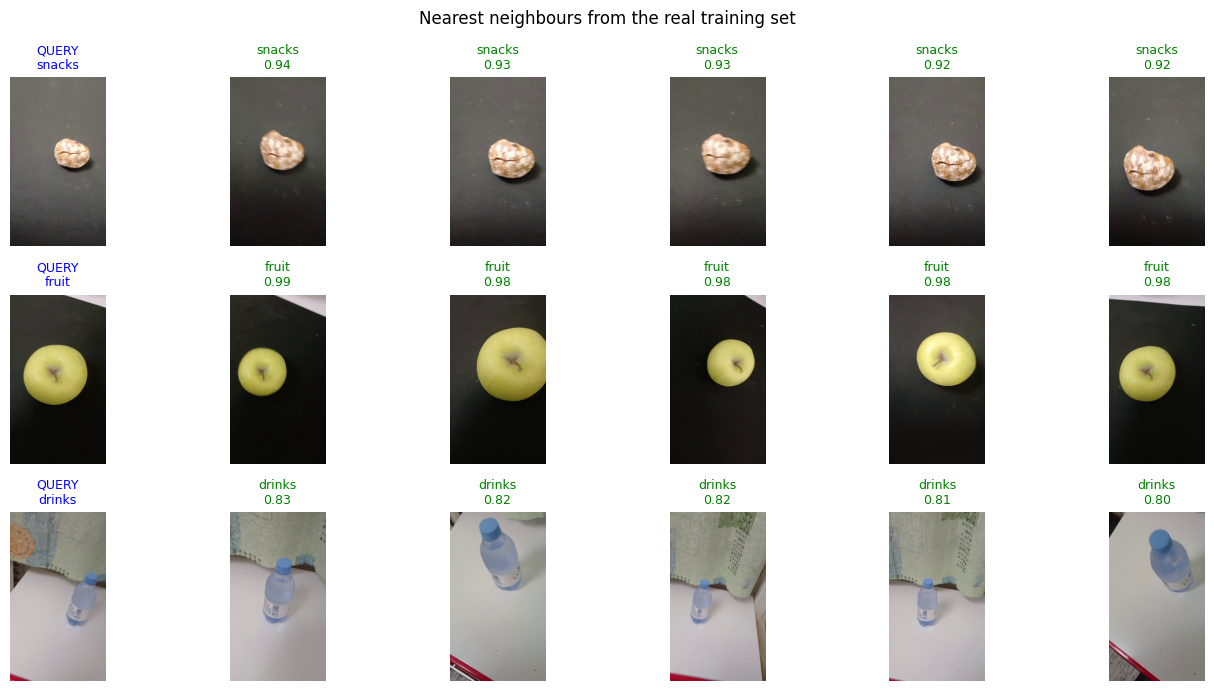

In [19]:
def embedder(base):
    out = tf.keras.layers.GlobalAveragePooling2D()(base.output)
    return tf.keras.Model(base.input, out)

def embed_paths(emb_model, paths, bs=32):
    vecs = []
    for i in range(0, len(paths), bs):
        batch = np.stack([load_img(p) for p in paths[i:i + bs]])
        vecs.append(emb_model.predict(batch, verbose=0))
    v = np.concatenate(vecs)
    return v / (np.linalg.norm(v, axis=1, keepdims=True) + 1e-8)

def precision_at_k(q, ql, g, gl, ks=(1, 5, 10)):
    order = np.argsort(-(q @ g.T), axis=1)
    return {f"P@{k}": float((gl[order[:, :k]] == ql[:, None]).mean()) for k in ks}

embed_model = embedder(best_base)
gallery_emb = embed_paths(embed_model, train_paths)
test_emb = embed_paths(embed_model, test_paths)
ft_pk = precision_at_k(test_emb, test_labels, gallery_emb, train_labels)

imagenet_base = tf.keras.applications.ConvNeXtTiny(include_top=False, weights="imagenet", input_shape=(224, 224, 3))
im_embed = embedder(imagenet_base)
im_pk = precision_at_k(embed_paths(im_embed, test_paths), test_labels,
                       embed_paths(im_embed, train_paths), train_labels)

retrieval = pd.DataFrame({"ImageNet backbone": im_pk, f"fine-tuned [{best['name']}]": ft_pk}).T
print(retrieval.round(4))
retrieval.to_csv(f"{RESULTS_DIR}/retrieval_pk.csv")

qs = rng.choice(len(test_paths), 3, replace=False)
plt.figure(figsize=(14, 7))
for r, qi in enumerate(qs):
    sims = gallery_emb @ test_emb[qi]
    nn_idx = np.argsort(-sims)[:5]
    ax = plt.subplot(3, 6, r * 6 + 1); ax.imshow(plt.imread(test_paths[qi])); ax.axis("off")
    ax.set_title(f"QUERY\n{class_names[test_labels[qi]]}", fontsize=9, color="blue")
    for c, gi in enumerate(nn_idx):
        ax = plt.subplot(3, 6, r * 6 + c + 2); ax.imshow(plt.imread(train_paths[gi])); ax.axis("off")
        ok = train_labels[gi] == test_labels[qi]
        ax.set_title(f"{class_names[train_labels[gi]]}\n{sims[gi]:.2f}", fontsize=9, color="green" if ok else "red")
plt.suptitle("Nearest neighbours from the real training set")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/knn_gallery.png", dpi=160)
plt.show()

In [21]:
def measure_latency(fn, x, n=50, warmup=5):
    for _ in range(warmup):
        fn(x)
    ts = []
    for _ in range(n):
        t = time.perf_counter(); fn(x); ts.append((time.perf_counter() - t) * 1000)
    return float(np.mean(ts)), float(np.std(ts))

sample = np.expand_dims(load_img(test_paths[0]), 0)
env = {
    "platform": platform.platform(),
    "python": platform.python_version(),
    "tensorflow": tf.__version__,
    "gpu": [g.name for g in tf.config.list_physical_devices("GPU")] or "none (CPU)",
}
print(env)

lat_rows = []

def add_row(nm, dev, mdl):
    with tf.device(dev):
        mean, std = measure_latency(lambda x, m=mdl: m(x, training=False).numpy(), sample)
    lat_rows.append({"model": nm, "device": dev, "latency_ms_mean": round(mean, 2),
                     "latency_ms_std": round(std, 2), "fps": round(1000 / mean, 1)})

for nm, mdl in [("A1 Baseline CNN", baseline_model), (f"ConvNeXt-Tiny [{best['name']}]", best_model)]:
    add_row(nm, "/GPU:0", mdl)
    try:
        with tf.device("/CPU:0"):
            cpu_mdl = tf.keras.models.clone_model(mdl)
            cpu_mdl.set_weights(mdl.get_weights())
        add_row(nm, "/CPU:0", cpu_mdl)
    except Exception as e:
        print("CPU measurement skipped for", nm, "->", repr(e)[:150])

latency = pd.DataFrame(lat_rows)
print(latency.to_string(index=False))
latency.to_csv(f"{RESULTS_DIR}/latency.csv", index=False)

{'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39', 'python': '3.13.16', 'tensorflow': '2.21.0', 'gpu': ['/physical_device:GPU:0']}
               model device  latency_ms_mean  latency_ms_std  fps
     A1 Baseline CNN /GPU:0            21.68            4.64 46.1
     A1 Baseline CNN /CPU:0            64.04           22.67 15.6
ConvNeXt-Tiny [real] /GPU:0          3049.88          830.56  0.3
ConvNeXt-Tiny [real] /CPU:0          1879.51          395.32  0.5


In [23]:
rng = np.random.RandomState(0)

def perturb(path):
    img = np.array(tf.keras.utils.load_img(path, target_size=IMG_SIZE), dtype=np.float32)
    h = rng.randint(130, 180); y0 = rng.randint(0, 224 - h); x0 = rng.randint(0, 224 - h)
    img = tf.image.resize(img[y0:y0 + h, x0:x0 + h], IMG_SIZE).numpy()      # случайный кроп
    k = rng.randint(4)
    if k == 0:   img = img * rng.uniform(0.35, 0.6)                          # тёмное фото
    elif k == 1: img = tf.image.adjust_contrast(img, 0.5).numpy() + 60       # пересвет
    elif k == 2: img = tf.nn.avg_pool2d(img[None], ksize=9, strides=1, padding="SAME")[0].numpy()  # размытие
    else:        img = img + rng.normal(0, 25, img.shape) + np.array([30, 0, -30])  # шум и цветовой сдвиг
    return np.clip(img, 0, 255).astype("float32")

X_hard = np.stack([perturb(p) for p in test_paths])
hard_labels = test_labels
hard_ds = tf.data.Dataset.from_tensor_slices((X_hard, hard_labels)).batch(BATCH_SIZE)

rows = []
for nm, mdl in [("A1 Baseline CNN", baseline_model)] + [(f"ConvNeXt [{r['name']}]", r["model"]) for r in runs]:
    m = compute_metrics(predict_probs(mdl, hard_ds), hard_labels)
    rows.append({"model": nm, **m})
hard_df = pd.DataFrame(rows)
print(hard_df.round(4).to_string(index=False))
hard_df.to_csv(f"{RESULTS_DIR}/hard_test_comparison.csv", index=False)

                model  accuracy(top-1)  top-2  macro_precision  macro_recall  macro_f1
      A1 Baseline CNN           0.6944 0.8056           0.7539        0.6944    0.7063
      ConvNeXt [real]           0.9444 0.9944           0.9545        0.9444    0.9449
ConvNeXt [real+synth]           0.9500 0.9944           0.9583        0.9500    0.9501


In [25]:
%pip install -q gradio

In [26]:
import gradio as gr
from PIL import Image, ImageDraw

gradcam = make_gradcam(best_model, best_base)
embed_model = embedder(best_base)
latencies = []
ENV_TEXT = f"{platform.platform()} | TF {tf.__version__} | GPU: {env['gpu']}"

def stamp_synthetic(img):
    img = img.convert("RGB").resize((256, 256))
    d = ImageDraw.Draw(img)
    d.rectangle([0, 0, 256, 22], fill=(200, 0, 0))
    d.text((6, 5), "SYNTHETIC / AI-GENERATED", fill=(255, 255, 255))
    return img

def classify(pil_img):
    if pil_img is None:
        return None, None, [], "Upload or capture a food photo.", ""
    t0 = time.perf_counter()
    img = np.array(pil_img.convert("RGB").resize(IMG_SIZE), dtype=np.float32)
    cam, probs = gradcam(img)
    q = embed_model(img[None], training=False).numpy()[0]
    q = q / (np.linalg.norm(q) + 1e-8)
    sims = gallery_emb @ q
    nn_idx = np.argsort(-sims)[:5]
    ms = (time.perf_counter() - t0) * 1000
    latencies.append(ms)

    overlay = Image.fromarray((overlay_cam(img, cam) * 255).astype("uint8"))
    gallery = [(Image.open(train_paths[i]).convert("RGB"), f"{class_names[train_labels[i]]} ({sims[i]:.2f})") for i in nn_idx]
    label = {class_names[i]: float(probs[i]) for i in range(num_classes)}
    info = (f"**Latency (this request, end-to-end incl. Grad-CAM + k-NN):** {ms:.0f} ms  \n"
            f"**Average over {len(latencies)} request(s):** {np.mean(latencies):.0f} ms  \n"
            f"**Environment:** {ENV_TEXT}  \n"
            f"**Model:** ConvNeXt-Tiny [{best['name']}]")
    return label, overlay, gallery, info, class_names[int(np.argmax(probs))]

def generate_similar(pred_class):
    if not pred_class:
        return [], "Classify an image first."
    for root, tag in [(SYNTH_ART_DIR, "ArtAug-enhanced"), (SYNTH_RAW_DIR, "raw")]:
        d = os.path.join(root, pred_class)
        if os.path.isdir(d):
            files = [f for f in os.listdir(d) if f.lower().endswith(IMG_EXT)]
            if files:
                pick = random.sample(files, min(4, len(files)))
                return [(stamp_synthetic(Image.open(os.path.join(d, f))), f"synthetic, {tag}") for f in pick], \
                       "These images are AI-generated (TA-TiTok + MaskGen, generated offline) and are not real photos."
    return [], "No offline-generated synthetic images found for this class (see §3)."

with gr.Blocks(title="Food classifier - A2") as demo:
    gr.Markdown("# Food classifier (bread / drinks / fruit / snacks)\n"
                "Upload a food photo or use the webcam. Do **not** upload photos of people without their consent; "
                "images are processed in memory and not stored. Images marked SYNTHETIC are AI-generated.")
    with gr.Row():
        inp = gr.Image(type="pil", sources=["upload", "webcam"], label="Food photo")
        with gr.Column():
            lbl = gr.Label(num_top_classes=num_classes, label="Prediction")
            cam_out = gr.Image(label="Grad-CAM (where the model looks)")
    info_md = gr.Markdown()
    nn_gal = gr.Gallery(label="Nearest neighbours (real training photos)", columns=5, height=230)
    state = gr.State("")
    btn = gr.Button("Generate similar (synthetic examples)")
    syn_gal = gr.Gallery(label="SYNTHETIC examples (AI-generated)", columns=4, height=260)
    syn_note = gr.Markdown()
    inp.change(classify, inp, [lbl, cam_out, nn_gal, info_md, state])
    btn.click(generate_similar, state, [syn_gal, syn_note])

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6b314b20d9b982682b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [24]:
baseline_model.save(f"{RESULTS_DIR}/baseline_cnn.keras")
best_model.save(f"{RESULTS_DIR}/convnext_tiny_best.keras")

metrics = {
    "classes": class_names,
    "selected_variant": best["name"],
    "baseline": baseline_metrics,
    "variants": {r["name"]: {"test": r["test"], "val_macro_f1": r["val_f1"], "val_loss": r["val_loss"], "data": r["data"]} for r in runs},
    "retrieval": {"imagenet_backbone": im_pk, "fine_tuned": ft_pk},
    "latency": lat_rows,
    "environment": env,
}
with open(f"{RESULTS_DIR}/metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

shutil.make_archive(f"{CONTENT}/results", "zip", RESULTS_DIR)
print("saved:", sorted(os.listdir(RESULTS_DIR)))

try:
    from google.colab import files
    files.download(f"{CONTENT}/results.zip")
except ImportError:
    print("Not in Colab - results are in", RESULTS_DIR)

saved: ['baseline_accuracy.png', 'baseline_cnn.keras', 'baseline_confusion_matrix.png', 'baseline_loss.png', 'convnext_real_accuracy.png', 'convnext_real_confusion_matrix.png', 'convnext_real_loss.png', 'convnext_real_synth_accuracy.png', 'convnext_real_synth_confusion_matrix.png', 'convnext_real_synth_loss.png', 'convnext_tiny_best.keras', 'dataset_examples.png', 'dataset_table.csv', 'gradcam_examples.png', 'hard_test_comparison.csv', 'knn_gallery.png', 'latency.csv', 'metrics.json', 'model_comparison.csv', 'model_comparison.png', 'retrieval_pk.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>